# 电商配送表现分析（E-commerce Delivery Performance Analysis）

## 项目目标

本项目基于 Olist 电商数据集，对订单配送表现进行探索性数据分析（EDA）。

主要希望回答以下问题：

- 订单通常需要多长时间完成配送？
- 有多少订单发生延迟配送？
- 延迟订单平均会延迟多少天？
- 商品数量、订单金额、运费等因素是否与配送延迟有关？

分析过程中主要使用 Python、Pandas 进行数据清洗、特征构建、数据聚合和多表合并，
并为后续 Dashboard 可视化准备核心指标。

In [1]:
import pandas as pd

## 1. 数据读取与初步探索（Data Loading & Exploration）

首先读取订单数据，并检查：

- 数据集的行数和列数
- 各字段的数据类型
- 缺失值情况
- 订单状态分布
- 日期字段是否能够正常用于时间计算

这一阶段的主要目的是了解数据结构，并发现可能影响后续分析的数据质量问题。

In [2]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
orders.shape

(99441, 8)

In [4]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [6]:
orders.isnull()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
99436,False,False,False,False,False,False,False,False
99437,False,False,False,False,False,False,False,False
99438,False,False,False,False,False,False,False,False
99439,False,False,False,False,False,False,False,False


In [7]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [8]:
orders.isnull().sum()/len(orders)*100

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [9]:
orders['order_status'].unique()

<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [10]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [11]:
missing_delivery = orders[
    orders['order_delivered_customer_date'].isnull()
]

missing_delivery.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
44,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaN,2018-06-28 00:00:00
103,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaN,NaN,2018-08-21 00:00:00
128,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaN,NaN,2017-10-03 00:00:00
154,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaN,2018-02-07 00:00:00


In [12]:
missing_delivery['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [13]:
delivered_but_missing = orders[(
    orders['order_status'] == 'delivered' 
)&
(orders['order_delivered_customer_date'].isnull())]

delivered_but_missing

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [14]:
delivered_but_missing.shape

(8, 8)

## 2. 数据质量检查（Data Quality Check）

在进行配送表现分析之前，首先检查订单数据的完整性和质量。

本阶段主要检查：

- 各字段的缺失值数量及缺失比例
- 订单状态的分布情况
- 已完成配送（delivered）订单中的关键字段是否存在缺失
- 可能影响后续配送时间计算的数据异常

对于存在缺失的配送相关字段，需要结合订单状态进一步判断，而不是直接删除。

In [15]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [16]:
orders.isnull().mean().sort_values(ascending=False)*100

order_delivered_customer_date    2.981668
order_delivered_carrier_date     1.793023
order_approved_at                0.160899
order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_estimated_delivery_date    0.000000
dtype: float64

In [17]:
orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [18]:
delivered_missing  = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isnull())
]

delivered_missing

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [19]:
delivered_missing[
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [20]:
delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notnull())
].copy()

delivered_orders.shape

(96470, 8)

In [21]:
delivered_orders[
    [
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'order_approved_at',
        'order_delivered_carrier_date'
    ]
].dtypes

order_purchase_timestamp         str
order_delivered_customer_date    str
order_estimated_delivery_date    str
order_approved_at                str
order_delivered_carrier_date     str
dtype: object

In [22]:
date_columns = delivered_orders[
    [
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'order_approved_at',
        'order_delivered_carrier_date'
    ]
]

for col in date_columns:
    delivered_orders[col] = pd.to_datetime(delivered_orders[col])

## 3. 配送时间分析（Delivery Time Analysis）

为了衡量订单从下单到实际送达所需要的时间，构建配送时间指标
`delivery_time_days`。

计算方式：

**配送时间 = 实际送达时间 - 下单时间**

通过该指标分析订单整体配送效率，并进一步检查配送时间的分布及潜在异常值

In [23]:
delivered_orders['delivery_time_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / 86400

In [24]:
delivered_orders['delivery_time_days'].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64

### 初步发现

已完成配送订单的平均配送时间约为 **12.56 天**，中位数约为 **10.22 天**。

平均值高于中位数，说明配送时间分布存在一定右偏，部分配送时间较长的订单拉高了整体平均值。

其中最长配送时间约为 **209.63 天**，明显高于正常配送时间，因此下一步需要进一步检查潜在异常值。

In [25]:
delivered_orders['delivery_time_days'].isna().sum()

np.int64(0)

In [26]:
delivered_orders['delivery_time_days'].min()

np.float64(0.5334143518518518)

In [27]:
delivered_orders['delivery_time_days'].max()

np.float64(209.6286111111111)

### 3.1 配送时间异常值检测（IQR Method）

由于配送时间的最大值明显高于正常水平，因此使用四分位距（IQR）方法识别潜在异常值。

计算方式：

**IQR = Q3 - Q1**

异常值判断范围：

- 下界：Q1 - 1.5 × IQR
- 上界：Q3 + 1.5 × IQR

需要注意的是，统计意义上的异常值并不一定代表错误数据。
对于配送业务而言，较长的配送时间可能反映真实的物流异常，因此需要进一步检查，而不是直接删除。

In [28]:
q1 = delivered_orders['delivery_time_days'].quantile(0.25)
q3 = delivered_orders['delivery_time_days'].quantile(0.75)

iqr = q3 - q1 

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print('Q1',q1)
print('Q3',q3)
print('IQR:', iqr)
print('Lower_bound:',lower_bound)
print('Upper_bound:',upper_bound)

Q1 6.766203703703704
Q3 15.720182291666667
IQR: 8.953978587962963
Lower_bound: -6.664764178240739
Upper_bound: 29.15115017361111


In [29]:
delivery_outliers = delivered_orders[
    (delivered_orders['delivery_time_days'] < lower_bound)|
    (delivered_orders['delivery_time_days'] > upper_bound)
]

delivery_outliers.shape

(4896, 9)

In [30]:
delivery_outliers.sort_values('delivery_time_days',ascending = False).head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,208.351759
61610,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,217906bc11a32c1e470eb7e08584894b,delivered,2017-03-08 18:09:02,2017-03-08 18:09:02,2017-03-13 08:54:02,2017-09-19 14:33:17,2017-04-17,194.850174
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,delivered,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,1a8a4a30dc296976717f44e7801fdeef,delivered,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,194.049583
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,delivered,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,8199345f57c6d1cbe9701f92481beb8d,delivered,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,188.134618
68769,c27815f7e3dd0b926b58552628481575,f85e9ec0719b16dc4dd0edd438793553,delivered,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,187.743843


#### 异常值检查结果

IQR 方法得到的配送时间上界约为 **29.15 天**，共有 **4,896 个订单**
被识别为潜在异常值。

部分订单的配送时间超过 190 天，最长约为 209.63 天。

这些记录虽然属于统计意义上的异常值，但可能反映真实的严重配送延迟。
因此，本分析暂时保留这些订单，而不是直接删除，并在后续延迟配送分析中进一步研究。

## 4. 延迟配送分析（Late Delivery Analysis）

配送时间较长并不一定意味着订单发生了延迟，因为不同订单的预计送达时间不同。

因此，本部分将实际送达日期与预计送达日期进行比较，构建以下指标：

- `delay_days`：实际送达日期与预计送达日期之间的时间差
- `is_late`：订单是否超过预计送达日期

其中：

- `delay_days < 0`：提前送达
- `delay_days > 0`：延迟送达

In [31]:
delivered_orders['delay_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

In [32]:
delivered_orders['delay_days'].describe()

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delay_days, dtype: float64

In [33]:
delivered_orders['is_late'] = (
    delivered_orders['delay_days'] > 0
)

In [34]:
delivered_orders['is_late'].value_counts()

is_late
False    88644
True      7826
Name: count, dtype: int64

In [35]:
delivered_orders['is_late'].value_counts(normalize= True) * 100

is_late
False    91.887633
True      8.112367
Name: proportion, dtype: float64

In [36]:
late_orders = delivered_orders[
    delivered_orders['is_late'] == True
]

In [37]:
late_orders['delay_days'].describe()

count    7826.000000
mean        9.551776
std        13.952540
min         0.002500
25%         1.867179
50%         5.806481
75%        11.820978
max       188.975081
Name: delay_days, dtype: float64

In [38]:
late_orders.sort_values(
    'delay_days',
    ascending = False
)[
    [
        'order_id',
        'order_purchase_timestamp',
        'order_estimated_delivery_date',
        'order_delivered_customer_date',
        'delivery_time_days',
        'delay_days'
    ]
].head(10)

,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,delivery_time_days,delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-03-15,2018-09-19 23:24:07,208.351759,188.975081
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-03-22,2017-09-19 14:36:39,209.628611,181.608785
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-01-19,2018-07-13 20:51:31,191.463542,175.869109
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-04-05,2017-09-19 17:00:07,189.863160,167.708414
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-04-06,2017-09-19 14:00:04,194.633611,166.583380
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-04-07,2017-09-19 15:12:50,195.634016,165.633912
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-04-10,2017-09-19 17:14:25,187.743843,162.718345
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-06-26,2017-12-04 18:36:29,175.223819,161.775336
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-04-11,2017-09-19 14:38:21,194.049583,161.609965
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-04-13,2017-09-19 14:38:18,188.134618,159.609931


In [39]:
avg_delay = late_orders['delay_days'].mean()

avg_delay

np.float64(9.551775917880569)

In [40]:
late_delivery_rate = delivered_orders['is_late'].mean() * 100
avg_delay = late_orders['delay_days'].mean()

print(f'Late Delivery Rate : {late_delivery_rate: .2f}%')
print(f'Average Delay: {avg_delay:.2f} days')

Late Delivery Rate :  8.11%
Average Delay: 9.55 days


### 4.1 核心配送 KPI（Delivery KPIs）

分析结果显示：

- **延迟配送率（Late Delivery Rate）：8.11%**
- **准时或提前送达率：91.89%**
- **延迟订单平均延迟时间（Average Delay）：9.55 天**

整体来看，大多数订单能够在预计日期前完成配送。

但约 **8.11%** 的订单存在延迟，并且发生延迟的订单平均超过预计日期约 **9.55 天**，
说明延迟订单虽然占比较低，但延迟程度仍然值得进一步分析。

## 5. 订单级特征构建（Order-Level Feature Engineering）

为了进一步分析影响配送延迟的潜在因素，本部分引入订单商品数据 `order_items`。

该数据集包含商品、卖家、价格、运费等信息，可以用于构建订单层面的业务特征。

在进行数据合并之前，需要首先确认不同数据表的数据粒度（Data Grain），
避免由于一对多关系导致订单被重复计算。

### 5.1 数据粒度检查（Data Grain Check）

`order_items` 数据集中的一行代表一个订单中的一个商品，而不是一个完整订单。

数据集中共有 **112,650 条商品记录**，但只有 **98,666 个唯一订单**，
说明部分订单包含多个商品。

因此，如果直接将 `order_items` 与订单表进行合并，
可能导致同一个订单出现多行，从而影响延迟配送率等订单级指标。

为保持“一行 = 一个订单”的分析粒度，需要先对商品数据进行聚合。

In [41]:
order_items = pd.read_csv('../data/olist_order_items_dataset.csv')

order_items.shape

(112650, 7)

In [42]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [43]:
order_items['order_id'].nunique()

98666

In [44]:
items_per_order = (
    order_items
    .groupby('order_id')
    .size()
    .reset_index(name = 'item_count')
)

items_per_order.head()

,order_id,item_count
0,00010242fe8c5a6d1ba2dd792cb16214,1
1,00018f77f2f0320c557190d7a144bdd3,1
2,000229ec398224ef6ca0657da4fc703e,1
3,00024acbcdf0a6daa1e931b038114c75,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1


In [45]:
items_per_order.shape

(98666, 2)

### 5.2 商品数据聚合（Order-Level Aggregation）

按照 `order_id` 对商品记录进行聚合，并构建三个订单级特征：

- `item_count`：订单包含的商品数量
- `total_price`：订单商品总金额
- `total_freight`：订单总运费

聚合后，每个 `order_id` 只保留一行，从而与订单数据保持一致的数据粒度

In [46]:
order_summary = (
    order_items
    .groupby('order_id')
    .agg(
        item_count = ('order_item_id','count'),
        total_price=('price','sum'),
        total_freight = ('freight_value','sum')
    )
    .reset_index()
)

order_summary.head()

,order_id,item_count,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [47]:
order_summary.shape

(98666, 4)

In [48]:
order_summary[['item_count','total_price','total_freight']].describe()

,item_count,total_price,total_freight
count,98666.000000,98666.000000,98666.000000
mean,1.141731,137.754076,22.823562
std,0.538452,210.645145,21.650909
min,1.000000,0.850000,0.000000
25%,1.000000,45.900000,13.850000
50%,1.000000,86.900000,17.170000
75%,1.000000,149.900000,24.040000
max,21.000000,13440.000000,1794.960000


### 5.3 合并订单与配送数据（Data Merge）

将订单级商品特征与配送数据通过 `order_id` 进行左连接（Left Join）。

合并后检查：

- 数据行数是否发生变化
- `order_id` 是否仍然唯一
- 新增字段是否存在缺失值

这些检查用于确认合并过程没有产生重复订单或数据丢失。

In [49]:
delivery_analysis = delivered_orders.merge(
    order_summary,
    on = 'order_id',
    how = 'left'
)

In [50]:
delivery_analysis.shape

(96470, 14)

In [51]:
delivery_analysis[
    ['item_count','total_price','total_freight']
].isna().sum()

item_count       0
total_price      0
total_freight    0
dtype: int64

In [52]:
delivery_analysis['order_id'].nunique()

96470

#### 合并结果

合并后的数据集包含 **96,470 个已完成配送订单**。

合并前后的订单数量保持一致，并且 `order_id` 仍然唯一；
`item_count`、`total_price` 和 `total_freight` 均不存在缺失值。

因此，本次合并没有产生订单重复或订单级数据丢失，
可以继续用于后续配送影响因素分析。

## 6. 配送延迟影响因素分析（Delivery Delay Factors）

### 6.1 商品数量与配送表现

In [53]:
delivery_analysis['item_count'].value_counts().sort_index()

item_count
1     86835
2      7392
3      1306
4       495
5       193
6       191
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [54]:
item_analysis = (
    delivery_analysis
    .groupby('item_count')
    .agg(
        order_count=('order_id','count'),
        late_delivery_rate=('is_late','mean'),
        avg_delivery_days=('delivery_time_days','mean')
    )
    .reset_index()
)

item_analysis['late_delivery_rate'] *= 100.0

item_analysis

,item_count,order_count,late_delivery_rate,avg_delivery_days
0,1,86835,8.288133,12.639136
1,2,7392,6.628788,11.826892
2,3,1306,6.202144,11.632372
3,4,495,5.656566,12.233637
4,5,193,6.735751,12.038005
5,6,191,8.376963,11.893492
6,7,22,0.000000,11.670133
7,8,8,0.000000,13.477030
8,9,3,0.000000,9.431424
9,10,8,0.000000,10.027878


In [55]:
delivery_analysis['item_group'] = pd.cut(
    delivery_analysis['item_count'],
    bins = [0,1,2,3,6,float('inf')],
    labels = ['1','2','3','4-6','7+']
)

In [56]:
item_group_analysis = (
    delivery_analysis 
    .groupby('item_group',observed= True)
    .agg(
        order_count = ('order_id','count'),
        late_delivery_rate =('is_late','mean'),
        avg_delivery_days =('delivery_time_days','mean'),
        avg_delay =('delay_days',lambda x : x[x>0].mean())
    )
    .reset_index()
)
item_group_analysis['late_delivery_rate'] *= 100.0

item_group_analysis

,item_group,order_count,late_delivery_rate,avg_delivery_days,avg_delay
0,1,86835,8.288133,12.639136,9.630608
1,2,7392,6.628788,11.826892,8.809526
2,3,1306,6.202144,11.632372,7.992139
3,4-6,879,6.484642,12.116771,8.296962
4,7+,58,1.724138,12.153383,3.752106


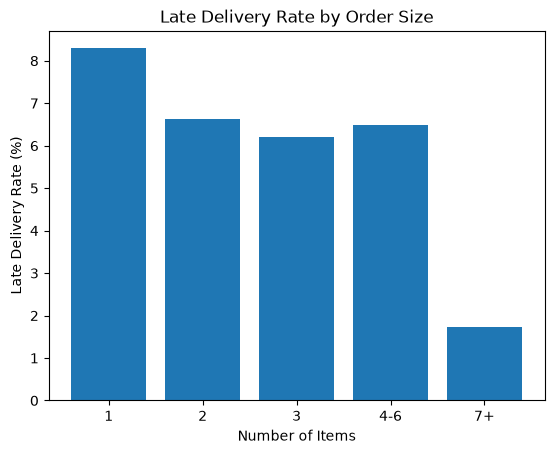

In [57]:
import matplotlib.pyplot as plt 

plt.bar(
    item_group_analysis['item_group'],
    item_group_analysis['late_delivery_rate']
)

plt.xlabel('Number of Items')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Late Delivery Rate by Order Size')

plt.show()

#### 分析结论

从订单规模来看，1 件商品订单的延迟配送率约为 **8.29%**，
而 2 件、3 件及 4–6 件商品订单的延迟率约为 **6%–7%**。

整体上没有观察到“商品数量增加导致延迟率持续上升”的趋势。

7 件及以上商品订单的延迟率仅约为 **1.72%**，
但该组只有 **58 个订单**，样本量较小，因此不宜据此认为大订单具有更好的配送表现。

综合来看，**商品数量与配送延迟之间暂未表现出明显的正向关系，
商品数量可能不是解释配送延迟的主要因素。**

### 6.2 运费与配送表现

In [58]:
order_freight=(order_items.groupby('order_id')['freight_value'].sum().reset_index())

In [59]:
order_freight.head()

,order_id,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,13.29
1,00018f77f2f0320c557190d7a144bdd3,19.93
2,000229ec398224ef6ca0657da4fc703e,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,18.14


In [60]:
freight_analysis = delivery_analysis.merge(
    order_freight,
    on = 'order_id',
    how = 'left',
    validate = 'one_to_one'
)

freight_analysis[
    ['order_id','freight_value','is_late']
].head()

,order_id,freight_value,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,8.72,False
1,53cdb2fc8bc7dce0b6741e2150273451,22.76,False
2,47770eb9100c2d0c44946d9cf07ec65d,19.22,False
3,949d5b44dbf5de918fe9c16f97b45f8a,27.20,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8.72,False


In [61]:
print('before merge:',len(delivery_analysis))
print('after merge:', len(freight_analysis))

print(
    'missing freight values:',
    freight_analysis['freight_value'].isna().sum()
)

print(
    'unique orders:',
    freight_analysis['order_id'].nunique()
)

before merge: 96470
after merge: 96470
missing freight values: 0
unique orders: 96470


In [62]:
freight_analysis['freight_group'] = pd.qcut(
    freight_analysis['freight_value'],
    q=4,
    duplicates='drop'
)

freight_analysis[
    ['freight_value','freight_group','is_late']
].head()

,freight_value,freight_group,is_late
0,8.72,"(-0.001, 13.85]",False
1,22.76,"(17.17, 24.02]",False
2,19.22,"(17.17, 24.02]",False
3,27.20,"(24.02, 1794.96]",False
4,8.72,"(-0.001, 13.85]",False


In [63]:
freight_summary = (
    freight_analysis
    .groupby('freight_group',observed=True)
    .agg(
        total_orders=('order_id','nunique'),
        late_rate = ('is_late','mean'),
        avg_freight =('freight_value','mean')
    )
    .reset_index()
)

freight_summary['late_rate_pct'] = (
    freight_summary['late_rate'] * 100
)

freight_summary 

,freight_group,total_orders,late_rate,avg_freight,late_rate_pct
0,"(-0.001, 13.85]",24153,0.060034,10.459786,6.003395
1,"(13.85, 17.17]",24091,0.081898,15.463615,8.189780
2,"(17.17, 24.02]",24112,0.090080,19.788770,9.007963
3,"(24.02, 1794.96]",24114,0.092519,45.443722,9.251887


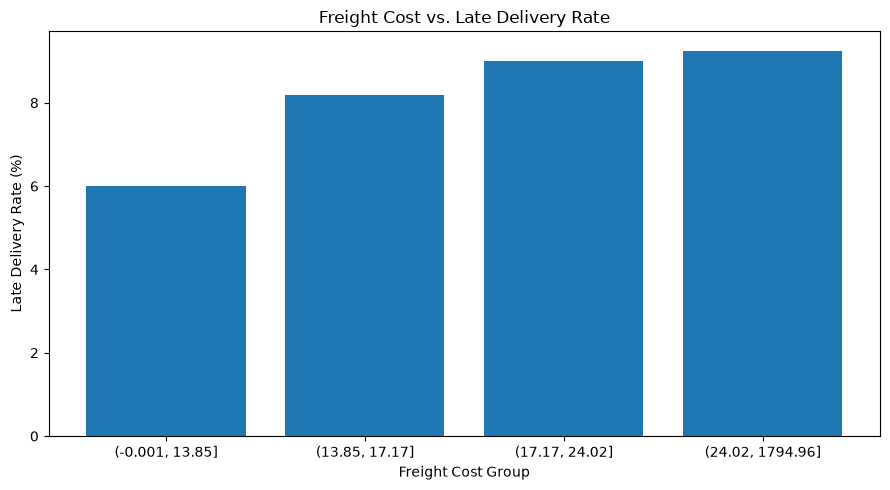

In [64]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(9,5))

plt.bar(
    freight_summary['freight_group'].astype(str),
    freight_summary['late_rate_pct']
)

plt.xlabel('Freight Cost Group')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Freight Cost vs. Late Delivery Rate')

plt.tight_layout()
plt.show()


6.2.2 运费水平与配送延迟率的关系

根据订单总运费的四分位数，将 96,470 笔订单划分为四个运费区间，并比较不同区间的配送延迟率。

分析结果显示，配送延迟率随运费水平升高呈逐步上升趋势。最低运费组的延迟率约为 6.00%，最高运费组约为 9.25%，两者相差约 3.25 个百分点。

这一结果表明，订单运费与配送延迟风险之间存在正向关联。但由于运费可能受到配送距离、商品重量、卖家位置等因素影响，因此不能据此认定运费升高会直接导致配送延迟。

后续可结合地区、配送距离及其他订单特征进一步分析，以判断这种关联是否依然存在。

# 6.3 配送距离与配送表现

In [65]:
import pandas as pd 

customers = pd.read_csv('../data/olist_customers_dataset.csv')
sellers = pd.read_csv('../data/olist_sellers_dataset.csv')
geolocation = pd.read_csv('../data/olist_geolocation_dataset.csv')

In [66]:
print('Customers:')
print(customers.columns.tolist())

print('\nSellers:')
print(sellers.columns.tolist())

print('\nGeolocation:')
print(geolocation.columns.tolist())

Customers:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Sellers:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Geolocation:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


In [67]:
geo_zip = (
    geolocation 
    .groupby('geolocation_zip_code_prefix')
    .agg(
        lat=('geolocation_lat','mean'),
        lng=('geolocation_lng','mean')
    )
    .reset_index()
)

In [68]:
customer_geo = customers.merge(
    geo_zip,
    left_on = 'customer_zip_code_prefix',
    right_on= 'geolocation_zip_code_prefix',
    how = 'left'
)

In [69]:
customer_geo = customer_geo.rename(
    columns={
        'lat':'customer_lat',
        'lng':'customer_lng'
    }
)

In [70]:
seller_geo = sellers.merge(
    geo_zip,
    left_on='seller_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how = 'left'
)

In [71]:
seller_geo = seller_geo.rename(
    columns={
        'lat':'seller_lat',
        'lng':'seller_lng'
    }
)

In [72]:
customer_geo[
    ['customer_id','customer_lat','customer_lng']
].head()

,customer_id,customer_lat,customer_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,-20.498489,-47.396929
1,18955e83d337fd6b2def6b18a428ac77,-23.727992,-46.542848
2,4e7b3e00288586ebd08712fdd0374a03,-23.531642,-46.656289
3,b2b6027bc5c5109e529d4dc6358b12c3,-23.499702,-46.185233
4,4f2d8ab171c80ec8364f7c12e35b23ad,-22.975100,-47.142925


In [73]:
seller_geo[
    ['seller_id','seller_lat','seller_lng']
]

,seller_id,seller_lat,seller_lng
0,3442f8959a84dea7ee197c632cb2df15,-22.893848,-47.061337
1,d1b65fc7debc3361ea86b5f14c68d2e2,-22.383437,-46.947927
2,ce3ad9de960102d0677a81f5d0bb7b2d,-22.909572,-43.177703
3,c0f3eea2e14555b6faeea3dd58c1b1c3,-23.657242,-46.612831
4,51a04a8a6bdcb23deccc82b0b80742cf,-22.964803,-46.534419
...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,-23.448041,-51.869960
3091,f8201cab383e484733266d1906e2fdfa,-27.656421,-48.665840
3092,74871d19219c7d518d0090283e03c137,-23.657851,-46.676925
3093,e603cf3fec55f8697c9059638d6c8eb5,-31.751072,-52.323202


In [74]:
order_customer = orders[
    ['order_id','customer_id']
].merge(
    customer_geo[
        ['customer_id','customer_lat','customer_lng']
    ],
    on = 'customer_id',
    how = 'left',
    validate='many_to_one'
)

order_customer.head()

,order_id,customer_id,customer_lat,customer_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,-23.576983,-46.587161
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,-12.177924,-44.660711
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,-16.745150,-48.514783
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,-5.774190,-35.271143
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,-23.676370,-46.514627


In [75]:
print('Rows:',len(order_customer))

print(
    'Missing customer coordinates:',
    order_customer[
        ['customer_lat','customer_lng']
    ].isna().any(axis=1).sum()
)

Rows: 99441
Missing customer coordinates: 278


In [76]:
item_seller = order_items[
    ['order_id','seller_id']
].merge(
    seller_geo[
        ['seller_id','seller_lat','seller_lng']
    ],
    on='seller_id',
    how = 'left',
    validate= 'many_to_one'
)

item_seller.head()

,order_id,seller_id,seller_lat,seller_lng
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,-22.496953,-44.127492
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,-23.565096,-46.518565
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,-22.262584,-46.171124
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,-20.553624,-47.387359
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,-22.929384,-53.135873


In [77]:
route_analysis = item_seller.merge(
    order_customer[
        ['order_id','customer_lat','customer_lng']
    ],
    on = 'order_id',
    how = 'left',
    validate= 'many_to_one'
)

route_analysis.head()

,order_id,seller_id,seller_lat,seller_lng,customer_lat,customer_lng
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,-22.496953,-44.127492,-21.762775,-41.309633
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,-23.565096,-46.518565,-20.220527,-50.903424
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,-22.262584,-46.171124,-19.870305,-44.593326
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,-20.553624,-47.387359,-23.089925,-46.611654
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,-22.929384,-53.135873,-23.243402,-46.827614


In [78]:
print(
    'Missing seller coordinates:',
    route_analysis[
        ['seller_lat','seller_lng']
    ].isna().any(axis=1).sum()
)

Missing seller coordinates: 253


In [79]:
print(
    'Rows with missing coordinates:',
    route_analysis[
        ['seller_lat','seller_lng','customer_lat','customer_lng']
    ].isna().any(axis=1).sum()
)

Rows with missing coordinates: 554


In [80]:
route_clean = route_analysis.dropna(
    subset=[
        'seller_lat',
        'seller_lng',
        'customer_lat',
        'customer_lng'
    ]
).copy()

print('Clean rows:',len(route_clean))

Clean rows: 112096


In [81]:
import numpy as np

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1 

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/ 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [82]:
route_clean['distance_km'] = haversine_distance(
    route_clean['seller_lat'],
    route_clean['seller_lng'],
    route_clean['customer_lat'],
    route_clean['customer_lng']
)

route_clean[['order_id','seller_id','distance_km']].head()

,order_id,seller_id,distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,301.504681
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,585.563937
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,312.343511
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,293.168420
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,646.163463


In [83]:
order_distance =(
    route_clean
    .groupby('order_id')
    .agg(
        avg_distance_km =('distance_km','mean'),
        max_distance_km =('distance_km','max'),
        seller_count=('seller_id','nunique')
    )
    .reset_index()
)

order_distance.head()

,order_id,avg_distance_km,max_distance_km,seller_count
0,00010242fe8c5a6d1ba2dd792cb16214,301.504681,301.504681,1
1,00018f77f2f0320c557190d7a144bdd3,585.563937,585.563937,1
2,000229ec398224ef6ca0657da4fc703e,312.343511,312.343511,1
3,00024acbcdf0a6daa1e931b038114c75,293.168420,293.168420,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,646.163463,646.163463,1


In [84]:
distance_analysis = delivery_analysis.merge(
    order_distance,
    on = 'order_id',
    how = 'left',
    validate= 'one_to_one'
)

distance_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,delay_days,is_late,item_count,total_price,total_freight,item_group,avg_distance_km,max_distance_km,seller_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,False,1,29.99,8.72,1,18.576110,18.576110,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,False,1,118.70,22.76,1,851.495069,851.495069,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,False,1,159.90,19.22,1,514.410666,514.410666,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,False,1,45.00,27.20,1,1822.226336,1822.226336,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,False,1,19.90,8.72,1,29.676625,29.676625,1.0


In [85]:
print('Rows:', len(distance_analysis))

print(
    'Missing distance:',
    distance_analysis['max_distance_km'].isna().sum()
)

print(
    'Unique orders:',
    distance_analysis['order_id'].nunique()
)

Rows: 96470
Missing distance: 476
Unique orders: 96470


In [86]:
distance_analysis['distance_group']=pd.qcut(
    distance_analysis['max_distance_km'],
    q=4,
    duplicates='drop'
)

In [87]:
distance_summary = (
    distance_analysis
    .dropna(subset=['distance_group'])
    .groupby('distance_group',observed=True)
    .agg(
        total_orders=('order_id','nunique'),
        late_rate = ('is_late','mean'),
        avg_distance_km=('max_distance_km','mean')
    )
    .reset_index()
)

distance_summary['late_rate_pct'] = (
    distance_summary['late_rate'] * 100
)

distance_summary 

,distance_group,total_orders,late_rate,avg_distance_km,late_rate_pct
0,"(-0.001, 189.329]",23999,0.063336,65.759138,6.333597
1,"(189.329, 435.633]",23999,0.074128,328.847940,7.412809
2,"(435.633, 800.292]",23997,0.082969,584.412811,8.296870
3,"(800.292, 8677.912]",23999,0.103588,1429.478952,10.358765


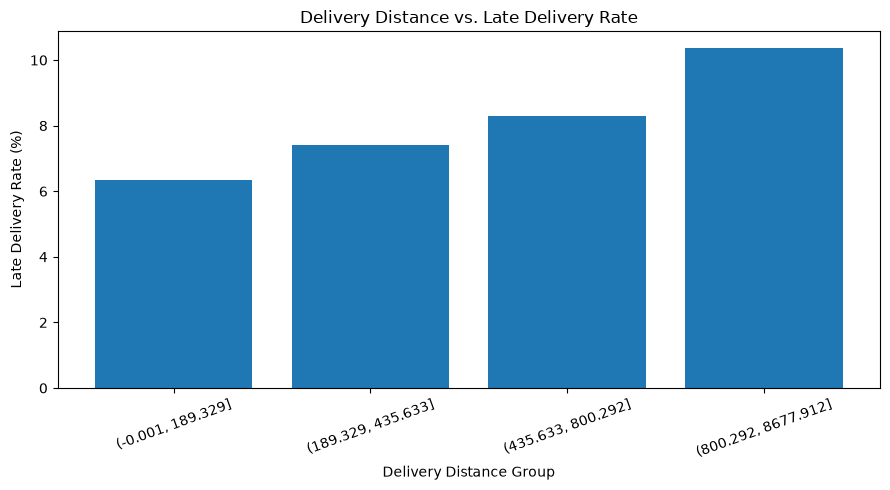

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.bar(
    distance_summary['distance_group'].astype(str),
    distance_summary['late_rate_pct']
)

plt.xlabel('Delivery Distance Group')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Delivery Distance vs. Late Delivery Rate')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 6.4 客户地区与延迟率

In [89]:
order_state = orders[
    ['order_id','customer_id']
].merge(
    customers[
        ['customer_id','customer_state']
    ],
    on = 'customer_id',
    how = 'left',
    validate = 'many_to_one'
)

order_state.head()

,order_id,customer_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,SP


In [90]:
state_analysis = delivery_analysis.merge(
    order_state[
        ['order_id','customer_state']
    ],
    on ='order_id',
    how = 'left',
    validate ='one_to_one'
)

state_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,delay_days,is_late,item_count,total_price,total_freight,item_group,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,False,1,29.99,8.72,1,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,False,1,118.70,22.76,1,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,False,1,159.90,19.22,1,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,False,1,45.00,27.20,1,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,False,1,19.90,8.72,1,SP


In [91]:
print('Rows:',len(state_analysis))
print('Missing customer state:', state_analysis['customer_state'].isna().sum())
print('Unique orders:', state_analysis['order_id'].nunique())

Rows: 96470
Missing customer state: 0
Unique orders: 96470


In [92]:
state_summary =(
    state_analysis
    .dropna(subset=['customer_state'])
    .groupby('customer_state',observed= True)
    .agg(
        total_orders =('order_id','nunique'),
        late_rate = ('is_late','mean')
    )
    .reset_index()
)

state_summary['late_rate_pct'] = (
    state_summary['late_rate'] * 100
)

In [93]:
state_summary_filtered = state_summary[
    state_summary['total_orders'] >= 500
].sort_values(
    'late_rate_pct',
    ascending= False
)

state_summary_filtered

,customer_state,total_orders,late_rate,late_rate_pct
9,MA,717,0.196653,19.665272
5,CE,1279,0.153245,15.324472
4,BA,3256,0.140356,14.035627
18,RJ,12350,0.134737,13.473684
13,PA,946,0.123679,12.367865
7,ES,1995,0.122306,12.230576
11,MS,701,0.115549,11.554922
14,PB,517,0.110251,11.025145
15,PE,1593,0.107972,10.797238
23,SC,3546,0.097575,9.757473


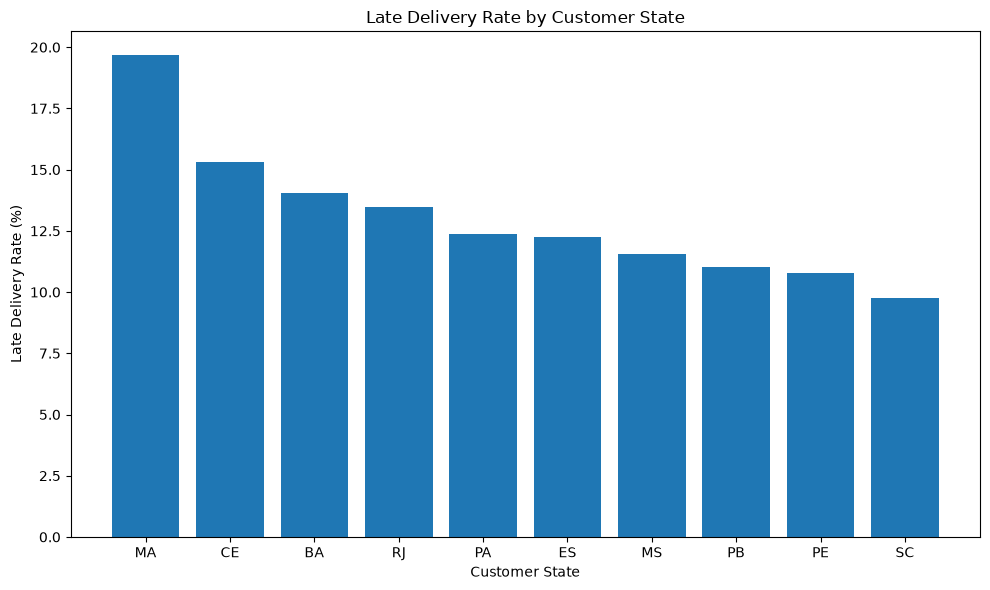

In [94]:
import matplotlib.pyplot as plt 
top_state = state_summary_filtered.head(10)

plt.figure(figsize=(10,6))

plt.bar(
    top_state['customer_state'],
    top_state['late_rate_pct']
)

plt.xlabel('Customer State')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Late Delivery Rate by Customer State')

plt.tight_layout()
plt.show()

不同客户州之间的配送延迟率存在明显差异，说明区域物流条件可能是影响配送表现的重要因素之一

# 6.5 下单月份与延迟率

In [95]:
delivery_analysis['order_purchase_timestamp'] = pd.to_datetime(
    delivery_analysis['order_purchase_timestamp']
)

delivery_analysis['order_month'] = (
    delivery_analysis['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

In [96]:
month_summary = (
    delivery_analysis
    .groupby('order_month')
    .agg(
        total_orders=('order_id','nunique'),
        late_rate =('is_late','mean')
    )
    .reset_index()
)

month_summary['late_rate_cpt'] = (
    month_summary['late_rate'] * 100
)

month_summary 

,order_month,total_orders,late_rate,late_rate_cpt
0,2016-09,1,1.000000,100.000000
1,2016-10,265,0.011321,1.132075
2,2016-12,1,0.000000,0.000000
3,2017-01,750,0.030667,3.066667
4,2017-02,1653,0.032063,3.206292
5,2017-03,2546,0.055774,5.577376
6,2017-04,2303,0.078593,7.859314
7,2017-05,3545,0.036107,3.610719
8,2017-06,3135,0.038596,3.859649
9,2017-07,3872,0.034349,3.434917


In [97]:
month_summary_filtered = month_summary[
    month_summary['total_orders'] >= 500
].copy()

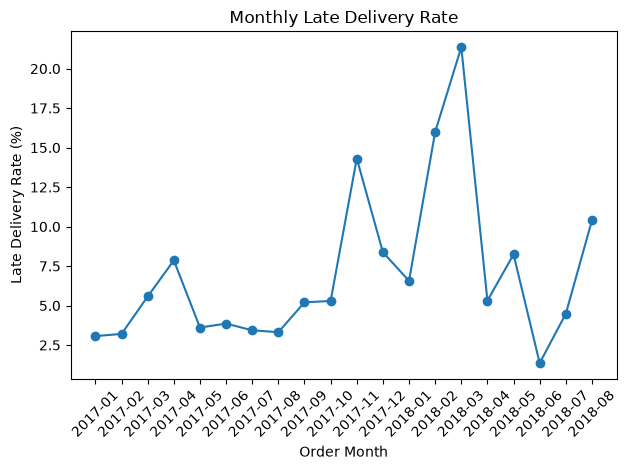

In [98]:
import matplotlib.pyplot as plt

plt.Figure(figsize=(12,5))

plt.plot(
    month_summary_filtered['order_month'],
    month_summary_filtered['late_rate_cpt'],
    marker = 'o'
)

plt.xlabel('Order Month')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Monthly Late Delivery Rate')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

配送延迟率在不同的月份之间存在明显波动，2017年末及2018年初出现较高峰值，说明配送表现受季节需求，物流压力或其他时间因素影响

# 6.6 EDA 总结（Exploratory Data Analysis Summary）

本项目围绕电商订单的配送表现与延迟影响因素进行了探索性数据分析，重点考察了订单商品数量、运费、配送距离、客户所在州以及下单月份与配送延迟率之间的关系。

1. 商品数量与配送延迟

分析结果显示，订单中的商品数量与配送延迟率之间未表现出明显、稳定的正向关系。因此，商品数量可能不是解释配送延迟的主要因素。

2. 运费与配送延迟

根据订单总运费四分位数分组后，延迟率随着运费水平上升而提高。最低运费组的延迟率约为 6.00%，最高运费组约为 9.25%。这表明运费与配送延迟之间存在正向关联，但不能据此推断因果关系。

3. 配送距离与配送延迟

配送距离与延迟率之间表现出更明显的正向关系。最低距离组的延迟率约为 6.33%，最高距离组约为 10.36%。这说明较长的配送距离可能与更高的延迟风险相关。

4. 客户州与配送延迟

不同客户州之间的延迟率差异明显。在订单量至少为 500 的州中，部分州的延迟率显著高于其他州，说明区域物流条件、地理位置及配送网络可能对配送表现产生重要影响。

5. 下单月份与配送延迟

配送延迟率在不同月份之间存在明显波动，并在部分月份出现较高峰值。这说明配送表现可能受到季节性需求、物流压力及其他时间相关因素影响。

Overall Findings

综合来看，配送延迟并非由单一因素决定。相比商品数量，配送距离、运费、区域差异以及时间因素与配送延迟表现出更明显的关联。

其中，配送距离与延迟率之间的关系尤其明显，同时较高运费订单也表现出更高的延迟率，因此配送距离可能是解释运费与延迟之间关系的重要因素之一。

需要注意的是，本阶段分析主要用于识别相关关系，不能直接推断因果关系。下一阶段将通过统计建模进一步分析不同因素在控制其他变量后的影响。

## 7. 统计建模：配送延迟影响因素分析

### 7.1 建模目标

在前面的探索性数据分析中，我们发现配送距离、运费、客户所在州以及下单时间等因素与配送延迟率存在一定关系。

本阶段将进一步使用逻辑回归模型，分析在同时控制多个因素的情况下，各变量与配送延迟之间的关系。

本项目的因变量为：

- `is_late`：订单是否延迟配送
  - 1 / True：延迟配送
  - 0 / False：未延迟配送

初步考虑的解释变量包括：

- `freight_value`：订单总运费
- `item_count`：订单商品数量
- `max_distance_km`：订单最长配送距离
- `customer_state`：客户所在州
- `order_month`：下单月份

### 7.2 建模数据集构建

为了保证建模结果的可解释性，本节将不同来源的订单特征整合到订单层面，并检查缺失值、变量类型以及目标变量分布。

建模数据集将保持“一行对应一个订单”的数据粒度，避免因表连接造成订单重复。

In [99]:
model_data = (
    delivery_analysis[
        ['order_id','is_late','order_purchase_timestamp']
    ]
    .merge(
        order_freight,
        on ='order_id',
        how = 'left' ,
        validate= 'one_to_one'
    )
    .merge(
        order_distance[
            ['order_id','max_distance_km']
        ],
        on = 'order_id',
        how ='left',
        validate='one_to_one'
    )
    .merge(
        order_state[
            ['order_id','customer_state']
        ],
        on = 'order_id',
        how = 'left',
        validate = 'one_to_one'
    )
)

In [100]:
[name for name , obj in globals().items() if isinstance(obj,pd.DataFrame)]

['_',
 '__',
 '___',
 'orders',
 '_2',
 '_6',
 'missing_delivery',
 '_11',
 'delivered_but_missing',
 '_13',
 'delivered_missing',
 '_18',
 '_19',
 'delivered_orders',
 'date_columns',
 'delivery_outliers',
 '_30',
 'late_orders',
 '_38',
 'order_items',
 '_42',
 'items_per_order',
 '_44',
 'order_summary',
 '_46',
 '_48',
 'delivery_analysis',
 'item_analysis',
 '_54',
 'item_group_analysis',
 '_56',
 'order_freight',
 '_59',
 'freight_analysis',
 '_60',
 '_62',
 'freight_summary',
 '_63',
 'customers',
 'sellers',
 'geolocation',
 'geo_zip',
 'customer_geo',
 'seller_geo',
 '_72',
 '_73',
 'order_customer',
 '_74',
 'item_seller',
 '_76',
 'route_analysis',
 '_77',
 'route_clean',
 '_82',
 'order_distance',
 '_83',
 'distance_analysis',
 '_84',
 'distance_summary',
 '_87',
 'order_state',
 '_89',
 'state_analysis',
 '_90',
 'state_summary',
 'state_summary_filtered',
 '_93',
 'top_state',
 'month_summary',
 '_96',
 'month_summary_filtered',
 'model_data']

In [101]:
items_per_order.columns.tolist()

['order_id', 'item_count']

In [102]:
model_data  = model_data.merge(
    items_per_order,
    on ='order_id',
    how = 'left',
    validate= 'one_to_one'
)

In [103]:
model_data['order_month'] = (
    pd.to_datetime(model_data['order_purchase_timestamp'])
    .dt.month
)

### 7.3 建模数据质量检查

在正式建模前，对建模数据集进行完整性检查，包括变量类型、缺失值情况以及目标变量分布。

由于配送延迟订单在全部订单中的占比较低，因此后续模型评估不能仅依赖准确率，还需要结合 Precision、Recall、F1-score 以及 ROC-AUC 等指标进行综合判断。

In [104]:
model_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  96470 non-null  str           
 1   is_late                   96470 non-null  bool          
 2   order_purchase_timestamp  96470 non-null  datetime64[us]
 3   freight_value             96470 non-null  float64       
 4   max_distance_km           95994 non-null  float64       
 5   customer_state            96470 non-null  str           
 6   item_count                96470 non-null  int64         
 7   order_month               96470 non-null  int32         
dtypes: bool(1), datetime64[us](1), float64(2), int32(1), int64(1), str(2)
memory usage: 4.9 MB


In [105]:
model_data.isna().sum()

order_id                      0
is_late                       0
order_purchase_timestamp      0
freight_value                 0
max_distance_km             476
customer_state                0
item_count                    0
order_month                   0
dtype: int64

In [106]:
model_data['is_late'].value_counts(normalize= True)

is_late
False    0.918876
True     0.081124
Name: proportion, dtype: float64

### 7.4 建模数据预处理与训练测试集划分

建模数据中仅配送距离变量存在少量缺失值。由于缺失比例较低，本阶段直接删除缺失配送距离的订单，以避免人为填补对模型结果造成额外影响。

目标变量 `is_late` 被转换为 0/1 形式，其中 1 表示延迟配送，0 表示未延迟配送。

由于延迟订单占比约为 8.11%，样本存在明显类别不平衡。因此，在划分训练集和测试集时使用分层抽样（stratified split），保证两部分数据中延迟订单比例基本一致。

第一版基准模型暂时使用数值型变量：
- `freight_value`
- `item_count`
- `max_distance_km`
- `order_month`

后续再加入 `customer_state` 等分类变量，比较模型表现是否改善。

In [107]:
model_clean = model_data.dropna(
    subset = ['max_distance_km']
).copy()

print(model_clean.shape)

(95994, 8)


In [108]:
model_clean['is_late'] = (
    model_clean['is_late']
    .astype(int)
)

In [109]:
X = model_clean[
    [
        'freight_value',
        'item_count',
        'max_distance_km',
        'order_month'
    ]
]

y = model_clean['is_late']

In [112]:
from sklearn.model_selection import train_test_split

X_train, X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y 
)

In [113]:
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

print('\nTrain late rate:')
print(y_train.value_counts(normalize=True))

print('\nTest late rate:')
print(y_test.value_counts(normalize=True))

Train shape: (76795, 4)
Test shape: (19199, 4)

Train late rate:
is_late
0    0.918992
1    0.081008
Name: proportion, dtype: float64

Test late rate:
is_late
0    0.919006
1    0.080994
Name: proportion, dtype: float64


### 7.5 基准逻辑回归模型

在完成训练集和测试集划分后，本节建立第一版基准逻辑回归模型。

模型暂时使用以下数值变量：
- `freight_value`
- `item_count`
- `max_distance_km`
- `order_month`

该模型主要用于建立一个可解释、可比较的基准结果，后续再逐步加入分类变量或其他特征，并比较模型表现是否得到改善。


In [114]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    class_weight= 'balanced'
)

log_model.fit(X_train, y_train )

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [115]:
y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

In [119]:
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test,y_pred))
print(
    'ROC-AUC:',
    roc_auc_score(y_test,y_prob)
)

              precision    recall  f1-score   support

           0       0.93      0.66      0.77     17644
           1       0.11      0.47      0.17      1555

    accuracy                           0.64     19199
   macro avg       0.52      0.56      0.47     19199
weighted avg       0.87      0.64      0.72     19199

ROC-AUC: 0.5722267154388219


In [120]:
from sklearn.metrics import average_precision_score

print(
    'PR-AUC:',
    average_precision_score(y_test, y_prob)
)

PR-AUC: 0.10728648415097067


### 7.6 加入客户地区变量的扩展模型

基准逻辑回归模型的 ROC-AUC 约为 0.57，PR-AUC 约为 0.11，说明仅使用运费、商品数量、配送距离和月份等基础变量时，模型对延迟订单的区分能力有限。

由于前面的探索性数据分析显示，不同客户州之间的配送延迟率存在明显差异，因此本节进一步加入 `customer_state` 变量，检验地区信息是否能够提升模型表现。

In [121]:
X2 = model_clean[
    [
        'freight_value',
        'item_count',
        'max_distance_km',
        'order_month',
        'customer_state'
    ]
].copy()

In [122]:
X2 = pd.get_dummies(
    X2, 
    columns=['customer_state'],
    drop_first=True
)

In [126]:
X2_train , X2_test , y2_train , y2_test = train_test_split(
    X2,
    y,
    test_size=0.2,
    random_state=42,
    stratify= y
)

In [127]:
log_model_2 = LogisticRegression(
    max_iter= 1000,
    class_weight= 'balanced'
)

log_model_2.fit(X2_train, y2_train)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [128]:
y2_pred = log_model_2.predict(X2_test)
y2_prob = log_model_2.predict_proba(X2_test)[:, 1]

In [129]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

print(classification_report(y2_test, y2_pred))

print(
    'ROC-AUC:',
    roc_auc_score(y2_test,y2_prob)
)

print(
    'PR-AUC:',
    average_precision_score(y2_test, y2_prob)
)

              precision    recall  f1-score   support

           0       0.94      0.70      0.80     17644
           1       0.13      0.50      0.20      1555

    accuracy                           0.68     19199
   macro avg       0.53      0.60      0.50     19199
weighted avg       0.87      0.68      0.75     19199

ROC-AUC: 0.6163247063574621
PR-AUC: 0.12800667997159756


### 7.7 模型结果对比

在基准逻辑回归模型的基础上加入客户所在州变量后，模型表现有所提升。

主要指标变化如下：

- ROC-AUC 从约 0.57 提升至约 0.62
- PR-AUC 从约 0.11 提升至约 0.13
- 延迟订单 Recall 从约 0.47 提升至约 0.50
- 延迟订单 F1-score 从约 0.17 提升至约 0.20

结果表明，客户地区信息对配送延迟具有一定额外解释和预测价值，这与前面的探索性数据分析结果一致。

但整体模型区分能力仍然有限，说明仅依靠当前订单特征仍不足以对配送延迟进行高质量预测。

### 7.8 随机森林模型

前两版逻辑回归模型已经建立了一个可解释的基准。加入客户地区变量后，模型表现有所提升，但整体区分能力仍然有限。

因此，本节进一步使用随机森林模型，检验是否存在逻辑回归难以捕捉的非线性关系或变量交互。

为保证模型之间可以公平比较，本节继续使用与扩展逻辑回归模型相同的特征、训练集和测试集，并使用 ROC-AUC、PR-AUC、Recall 和 F1-score 等指标进行评估。